In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_excel("Dataset_1.xlsx")

c:\Users\ankit\anaconda3\envs\venv\lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
c:\Users\ankit\anaconda3\envs\venv\lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


In [4]:
df.head()

,Student_ID,Age,Gender,Department,Year_of_Study,Residence_Type,Parent_Education,Internet_Access,Part_Time_Job,Study_Hours_Per_Day,...,Attendance_Percentage,Assignment_Delay_Days,Internal_Marks_50,Previous_GPA_10,Monthly_Family_Income_INR,Stress_Level_10,Placement_Interest,Final_Exam_Score_100,Result,Admission_Date
0,STU-01046,22.0,Female,Mechanical,1,With Family,School,Yes,No,2.73,...,100.00,1,39.47,8.72,37752.95,1.48,Higher Studies,100.00,Pass,2024-06-12
1,STU-01198,20.0,Female,Computer Science,2,Rented Accommodation,School,Yes,No,1.41,...,78.35,2,40.46,7.94,NaN,3.99,Private Job,100.00,Pass,2026-03-09
2,STU-00203,21.0,Male,Electronics,1,Rented Accommodation,Graduate,Yes,No,5.90,...,86.26,1,43.43,7.57,40821.73,2.97,Government Job,100.00,Pass,2026-05-21
3,STU-00822,17.0,Female,Computer Science,4,With Family,Graduate,Yes,No,0.84,...,57.31,1,26.15,6.63,37808.23,3.44,Higher Studies,69.60,Pass,2024-12-02
4,STU-00638,23.0,Male,Civil,3,Hostel,School,Yes,No,2.28,...,79.46,0,40.66,6.43,17638.59,4.32,Undecided,89.05,Pass,2025-03-06


In [5]:
df.tail()

,Student_ID,Age,Gender,Department,Year_of_Study,Residence_Type,Parent_Education,Internet_Access,Part_Time_Job,Study_Hours_Per_Day,...,Attendance_Percentage,Assignment_Delay_Days,Internal_Marks_50,Previous_GPA_10,Monthly_Family_Income_INR,Stress_Level_10,Placement_Interest,Final_Exam_Score_100,Result,Admission_Date
1215,STU-00391,23.0,Female,Civil,1,Hostel,Graduate,Yes,No,NaN,...,70.63,2,48.53,5.83,203608.49,5.05,Private Job,100.00,Pass,2025-03-11
1216,STU-00426,18.0,Male,Science,3,With Family,Postgraduate,Yes,No,1.82,...,63.22,0,35.69,6.52,15621.20,2.07,Private Job,66.57,Pass,2023-06-20
1217,STU-00125,22.0,Female,Electronics,1,With Family,Graduate,Yes,No,1.83,...,80.14,12,33.90,7.35,58218.07,7.35,Private Job,71.14,Pass,2022-07-11
1218,STU-00964,20.0,Male,Electronics,1,Rented Accommodation,School,Yes,No,3.09,...,75.76,12,30.11,9.08,NaN,9.30,Private Job,75.54,Pass,2025-08-16
1219,STU-00339,19.0,Male,Business Administration,1,With Family,Postgraduate,Yes,No,2.15,...,NaN,0,31.99,6.92,57395.98,3.27,Private Job,81.07,Pass,2024-04-12


In [6]:
df.shape

(1220, 22)

In [7]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Department', 'Year_of_Study',
       'Residence_Type', 'Parent_Education', 'Internet_Access',
       'Part_Time_Job', 'Study_Hours_Per_Day', 'Sleep_Hours_Per_Day',
       'Social_Media_Hours_Per_Day', 'Attendance_Percentage',
       'Assignment_Delay_Days', 'Internal_Marks_50', 'Previous_GPA_10',
       'Monthly_Family_Income_INR', 'Stress_Level_10', 'Placement_Interest',
       'Final_Exam_Score_100', 'Result', 'Admission_Date'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1220 entries, 0 to 1219
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Student_ID                  1220 non-null   object        
 1   Age                         1196 non-null   float64       
 2   Gender                      1202 non-null   object        
 3   Department                  1189 non-null   object        
 4   Year_of_Study               1220 non-null   int64         
 5   Residence_Type              1183 non-null   object        
 6   Parent_Education            1172 non-null   object        
 7   Internet_Access             1202 non-null   object        
 8   Part_Time_Job               1220 non-null   object        
 9   Study_Hours_Per_Day         1160 non-null   float64       
 10  Sleep_Hours_Per_Day         1179 non-null   float64       
 11  Social_Media_Hours_Per_Day  1166 non-null   float64     

In [9]:
df.describe(include="all")

,Student_ID,Age,Gender,Department,Year_of_Study,Residence_Type,Parent_Education,Internet_Access,Part_Time_Job,Study_Hours_Per_Day,...,Attendance_Percentage,Assignment_Delay_Days,Internal_Marks_50,Previous_GPA_10,Monthly_Family_Income_INR,Stress_Level_10,Placement_Interest,Final_Exam_Score_100,Result,Admission_Date
count,1220,1196.000000,1202,1189,1220.000000,1183,1172,1202,1220,1160.000000,...,1153.000000,1220.000000,1171.000000,1183.000000,1.149000e+03,1178.000000,1195,1220.000000,1220,1220
unique,1200,NaN,3,7,NaN,3,4,2,2,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN,2,NaN
top,STU-00523,NaN,Male,Computer Science,NaN,With Family,Graduate,Yes,No,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Private Job,NaN,Pass,NaN
freq,2,NaN,610,255,NaN,501,489,1073,948,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,512,NaN,1219,NaN
mean,NaN,20.626254,NaN,NaN,2.412295,NaN,NaN,NaN,NaN,3.789707,...,78.814848,2.198361,42.376114,7.524641,8.205130e+04,3.952750,NaN,92.637057,NaN,2024-07-09 05:31:40.327868672
min,NaN,17.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,0.410000,...,0.000000,0.000000,15.460000,4.410000,8.000000e+03,1.000000,NaN,-10.000000,NaN,2022-07-03 00:00:00
25%,NaN,19.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,2.010000,...,70.430000,1.000000,37.665000,6.730000,3.398979e+04,2.415000,NaN,88.057500,NaN,2023-07-15 18:00:00
50%,NaN,21.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,3.220000,...,79.070000,2.000000,43.320000,7.520000,5.577452e+04,3.750000,NaN,99.890000,NaN,2024-07-21 12:00:00
75%,NaN,22.000000,NaN,NaN,3.000000,NaN,NaN,NaN,NaN,4.872500,...,87.550000,3.000000,49.415000,8.255000,9.628018e+04,5.210000,NaN,100.000000,NaN,2025-07-27 06:00:00
max,NaN,48.000000,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,24.000000,...,175.000000,13.000000,50.000000,10.000000,2.883511e+06,10.000000,NaN,125.000000,NaN,2026-06-29 00:00:00


In [10]:
df.dtypes

Student_ID                            object
Age                                  float64
Gender                                object
Department                            object
Year_of_Study                          int64
Residence_Type                        object
Parent_Education                      object
Internet_Access                       object
Part_Time_Job                         object
Study_Hours_Per_Day                  float64
Sleep_Hours_Per_Day                  float64
Social_Media_Hours_Per_Day           float64
Attendance_Percentage                float64
Assignment_Delay_Days                  int64
Internal_Marks_50                    float64
Previous_GPA_10                      float64
Monthly_Family_Income_INR            float64
Stress_Level_10                      float64
Placement_Interest                    object
Final_Exam_Score_100                 float64
Result                                object
Admission_Date                datetime64[ns]
dtype: obj

In [11]:
numerical_columns = df.select_dtypes(include=['int64','float64']).columns

categorical_columns = df.select_dtypes(include=['object']).columns

print(numerical_columns)

print(categorical_columns)

Index(['Age', 'Year_of_Study', 'Study_Hours_Per_Day', 'Sleep_Hours_Per_Day',
       'Social_Media_Hours_Per_Day', 'Attendance_Percentage',
       'Assignment_Delay_Days', 'Internal_Marks_50', 'Previous_GPA_10',
       'Monthly_Family_Income_INR', 'Stress_Level_10', 'Final_Exam_Score_100'],
      dtype='object')
Index(['Student_ID', 'Gender', 'Department', 'Residence_Type',
       'Parent_Education', 'Internet_Access', 'Part_Time_Job',
       'Placement_Interest', 'Result'],
      dtype='object')


In [12]:
df.isnull().sum()

Student_ID                     0
Age                           24
Gender                        18
Department                    31
Year_of_Study                  0
Residence_Type                37
Parent_Education              48
Internet_Access               18
Part_Time_Job                  0
Study_Hours_Per_Day           60
Sleep_Hours_Per_Day           41
Social_Media_Hours_Per_Day    54
Attendance_Percentage         67
Assignment_Delay_Days          0
Internal_Marks_50             49
Previous_GPA_10               37
Monthly_Family_Income_INR     71
Stress_Level_10               42
Placement_Interest            25
Final_Exam_Score_100           0
Result                         0
Admission_Date                 0
dtype: int64

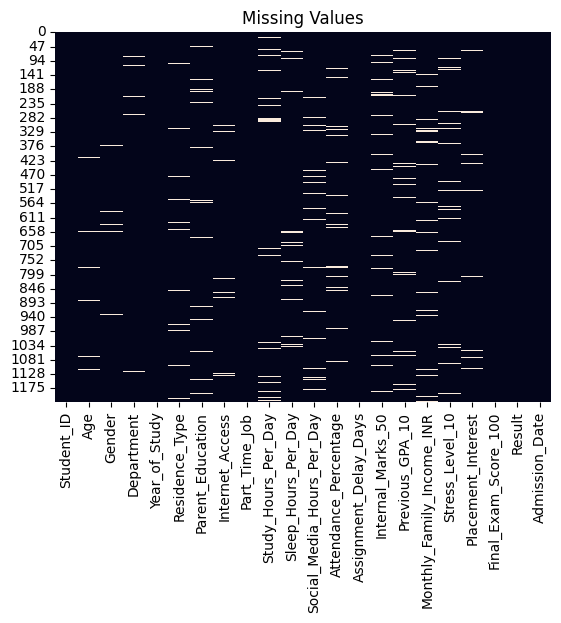

In [13]:
sns.heatmap(df.isnull(),cbar=False)
plt.title("Missing Values")
plt.show()

In [14]:
df = df.dropna()

# Observation:
# • Missing values have been removed.
# • The dataset is now complete for further analysis.

In [15]:
df.duplicated().sum()

np.int64(14)

In [16]:
df = df.drop_duplicates()

# Observation:
# • Duplicate records have been removed.
# • Every row now represents a unique student.

In [17]:
df["Admission_Date"] = pd.to_datetime(df["Admission_Date"])

In [18]:
df.describe()

,Age,Year_of_Study,Study_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Media_Hours_Per_Day,Attendance_Percentage,Assignment_Delay_Days,Internal_Marks_50,Previous_GPA_10,Monthly_Family_Income_INR,Stress_Level_10,Final_Exam_Score_100,Admission_Date
count,698.000000,698.000000,698.000000,698.000000,698.000000,698.000000,698.00000,698.000000,698.000000,6.980000e+02,698.000000,698.000000,698
mean,20.643266,2.469914,3.662393,6.829241,2.074155,78.513152,2.15616,42.168854,7.525072,8.880761e+04,3.948782,92.509370,2024-07-23 04:40:34.383953920
min,17.000000,1.000000,0.470000,0.500000,0.000000,0.000000,0.00000,15.780000,4.410000,8.000000e+03,1.000000,-5.000000,2022-07-03 00:00:00
25%,19.000000,1.000000,1.987500,6.030000,0.602500,69.580000,1.00000,37.717500,6.720000,3.378538e+04,2.400000,88.095000,2023-07-22 12:00:00
50%,21.000000,2.000000,3.120000,6.830000,1.350000,78.460000,2.00000,43.140000,7.555000,5.579995e+04,3.745000,99.190000,2024-08-10 00:00:00
75%,22.000000,3.000000,4.747500,7.650000,2.852500,88.372500,3.00000,49.267500,8.257500,9.624176e+04,5.227500,100.000000,2025-08-18 06:00:00
max,48.000000,4.000000,24.000000,9.940000,28.000000,175.000000,13.00000,50.000000,10.000000,2.883511e+06,10.000000,100.000000,2026-06-29 00:00:00
std,2.587957,1.111998,2.474643,1.214540,2.467861,14.371064,2.16400,7.109482,1.094682,2.029037e+05,2.076841,10.965835,NaN


In [19]:
df.mean(numeric_only=True)

Age                              20.643266
Year_of_Study                     2.469914
Study_Hours_Per_Day               3.662393
Sleep_Hours_Per_Day               6.829241
Social_Media_Hours_Per_Day        2.074155
Attendance_Percentage            78.513152
Assignment_Delay_Days             2.156160
Internal_Marks_50                42.168854
Previous_GPA_10                   7.525072
Monthly_Family_Income_INR     88807.610874
Stress_Level_10                   3.948782
Final_Exam_Score_100             92.509370
dtype: float64

In [20]:
df.median(numeric_only=True)

Age                              21.000
Year_of_Study                     2.000
Study_Hours_Per_Day               3.120
Sleep_Hours_Per_Day               6.830
Social_Media_Hours_Per_Day        1.350
Attendance_Percentage            78.460
Assignment_Delay_Days             2.000
Internal_Marks_50                43.140
Previous_GPA_10                   7.555
Monthly_Family_Income_INR     55799.950
Stress_Level_10                   3.745
Final_Exam_Score_100             99.190
dtype: float64

In [21]:
df.mode().iloc[0]

Student_ID                              STU-00003
Age                                          21.0
Gender                                       Male
Department                       Computer Science
Year_of_Study                                 2.0
Residence_Type                        With Family
Parent_Education                         Graduate
Internet_Access                               Yes
Part_Time_Job                                  No
Study_Hours_Per_Day                          2.11
Sleep_Hours_Per_Day                          6.43
Social_Media_Hours_Per_Day                   0.86
Attendance_Percentage                       100.0
Assignment_Delay_Days                         1.0
Internal_Marks_50                            50.0
Previous_GPA_10                              10.0
Monthly_Family_Income_INR                  8000.0
Stress_Level_10                               1.0
Placement_Interest                    Private Job
Final_Exam_Score_100                        100.0


In [22]:
df.std(numeric_only=True)

Age                                2.587957
Year_of_Study                      1.111998
Study_Hours_Per_Day                2.474643
Sleep_Hours_Per_Day                1.214540
Social_Media_Hours_Per_Day         2.467861
Attendance_Percentage             14.371064
Assignment_Delay_Days              2.164000
Internal_Marks_50                  7.109482
Previous_GPA_10                    1.094682
Monthly_Family_Income_INR     202903.652290
Stress_Level_10                    2.076841
Final_Exam_Score_100              10.965835
dtype: float64

In [23]:
df.var(numeric_only=True)

Age                           6.697523e+00
Year_of_Study                 1.236540e+00
Study_Hours_Per_Day           6.123859e+00
Sleep_Hours_Per_Day           1.475107e+00
Social_Media_Hours_Per_Day    6.090339e+00
Attendance_Percentage         2.065275e+02
Assignment_Delay_Days         4.682896e+00
Internal_Marks_50             5.054473e+01
Previous_GPA_10               1.198329e+00
Monthly_Family_Income_INR     4.116989e+10
Stress_Level_10               4.313270e+00
Final_Exam_Score_100          1.202495e+02
dtype: float64

In [24]:
df.skew(numeric_only=True)

Age                            3.362209
Year_of_Study                  0.044535
Study_Hours_Per_Day            2.417985
Sleep_Hours_Per_Day           -0.297886
Social_Media_Hours_Per_Day     4.413597
Attendance_Percentage          0.006399
Assignment_Delay_Days          1.508620
Internal_Marks_50             -0.802733
Previous_GPA_10                0.032558
Monthly_Family_Income_INR     10.593451
Stress_Level_10                0.570066
Final_Exam_Score_100          -2.295426
dtype: float64

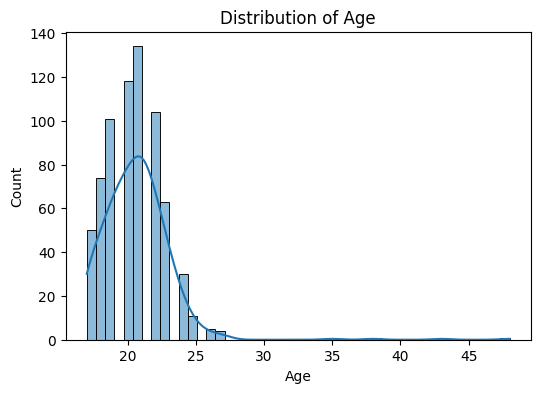

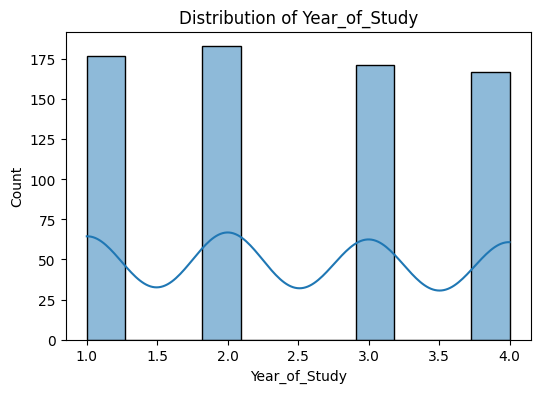

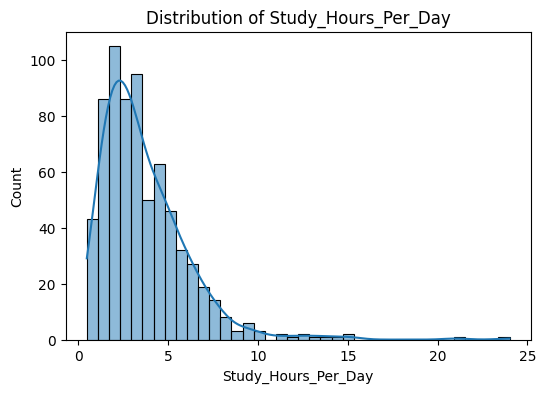

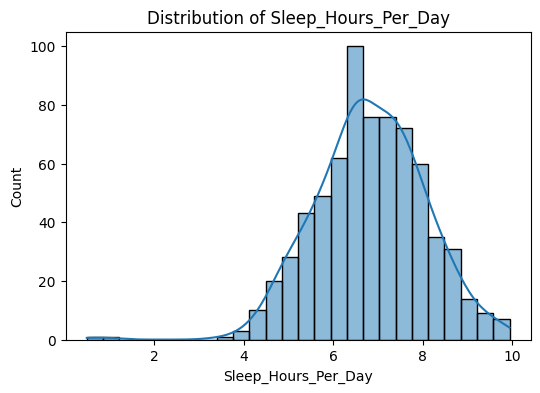

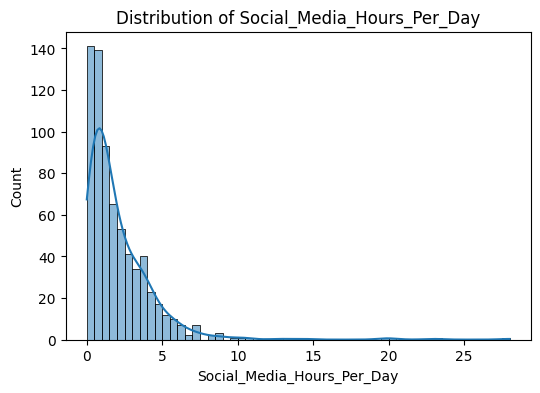

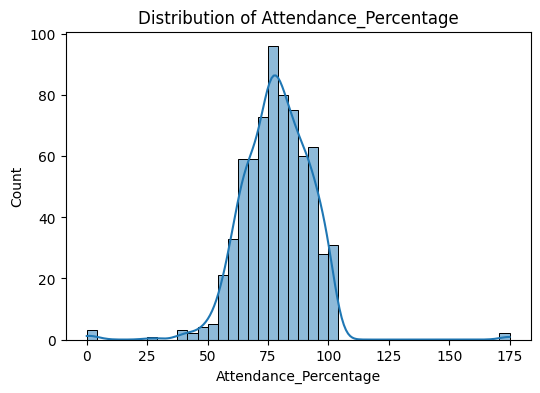

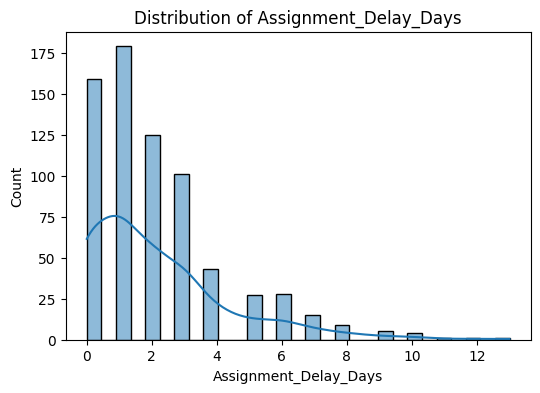

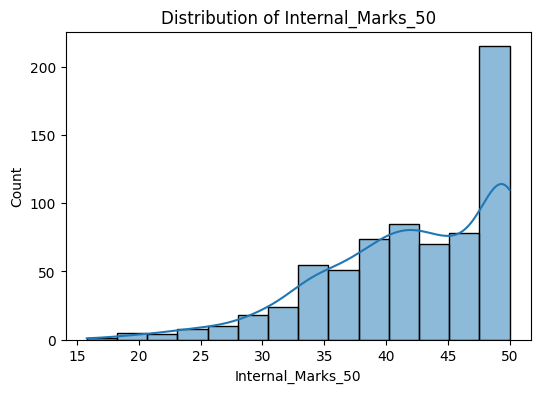

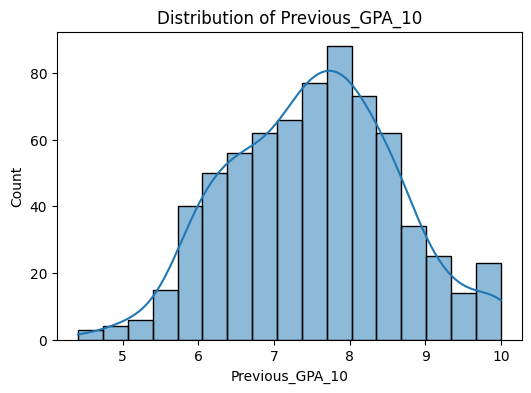

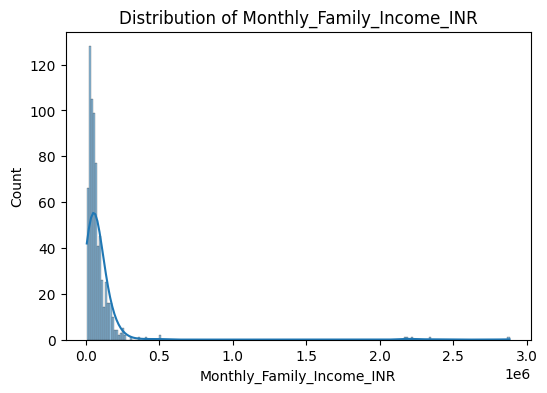

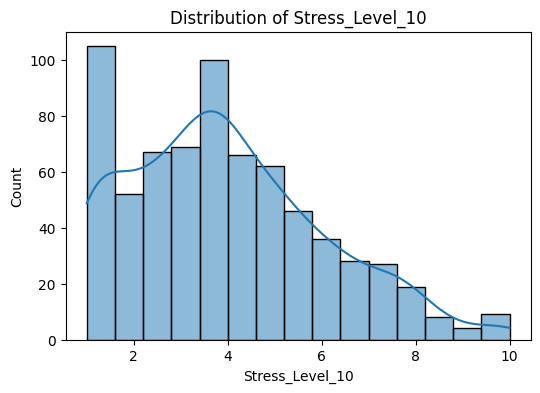

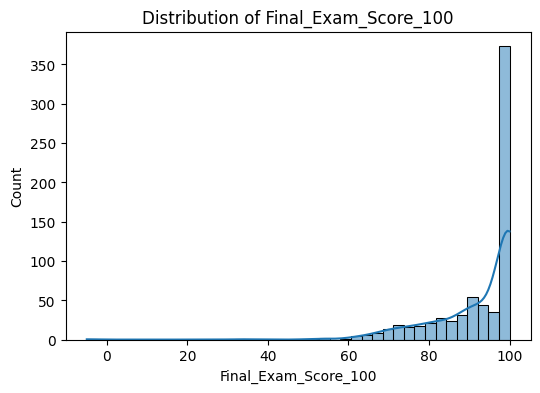

In [ ]:
for col in numerical_columns:

    plt.figure(figsize=(6,4))

    sns.histplot(df[col],kde=True)

    plt.title(f"Distribution of {col}")

    plt.show()

    # Observation:
    # • The distribution of each numerical column is visualized.
    
   

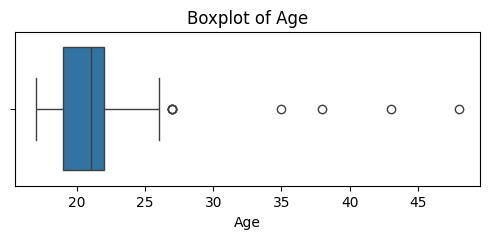

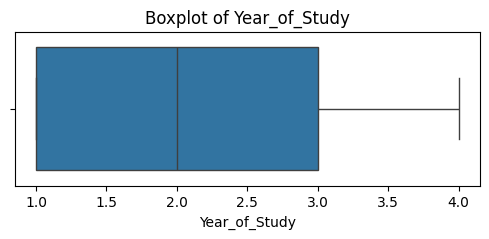

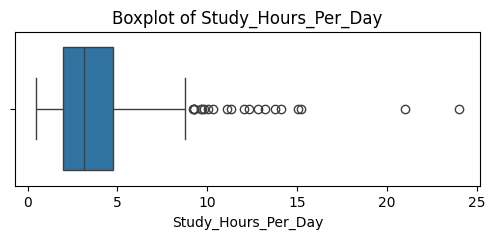

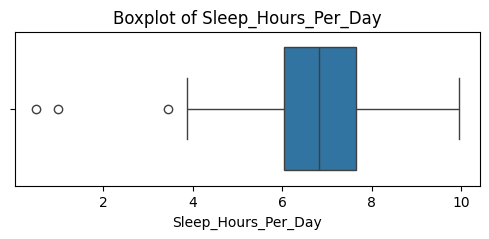

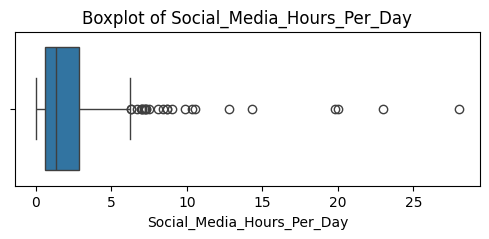

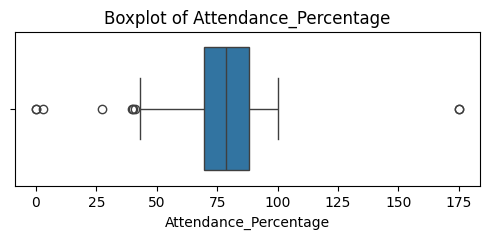

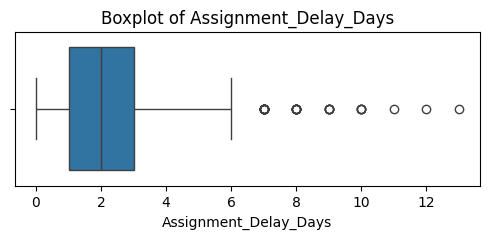

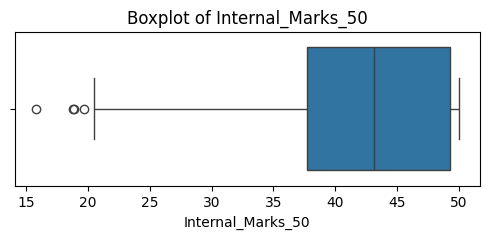

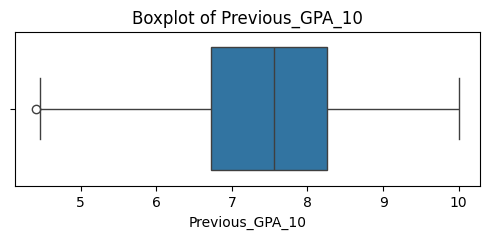

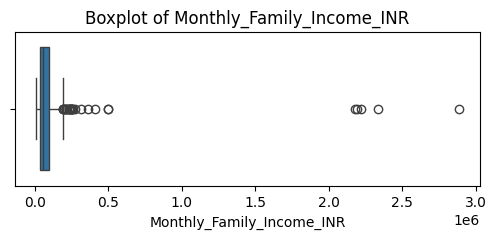

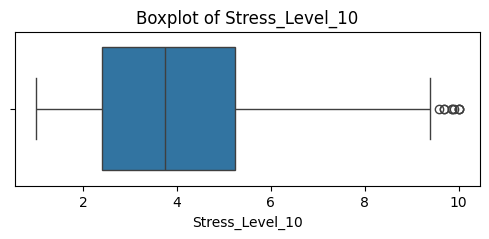

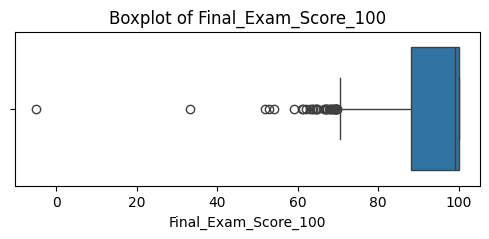

In [26]:
for col in numerical_columns:

    plt.figure(figsize=(6,2))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")

    plt.show()


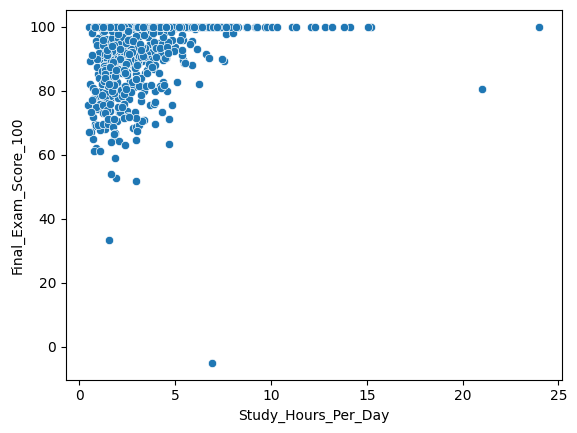

In [27]:
sns.scatterplot(x="Study_Hours_Per_Day",
                y="Final_Exam_Score_100",
                data=df)

plt.show()


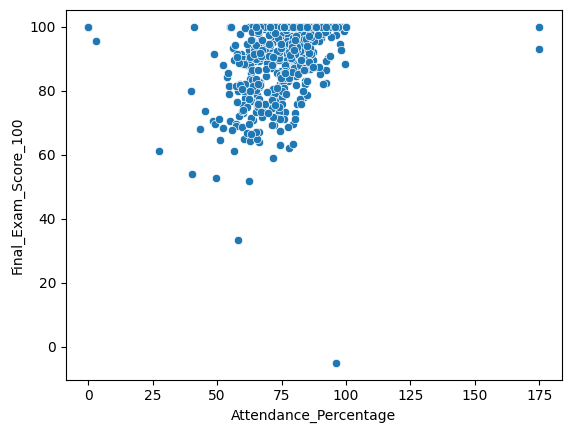

In [28]:
sns.scatterplot(x="Attendance_Percentage",
                y="Final_Exam_Score_100",
                data=df)

plt.show()


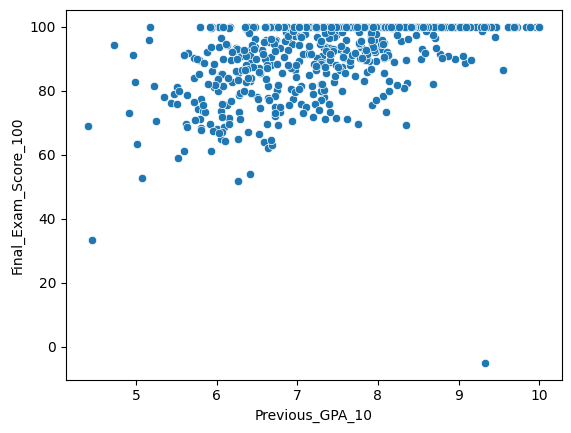

In [29]:
sns.scatterplot(x="Previous_GPA_10",
                y="Final_Exam_Score_100",
                data=df)

plt.show()

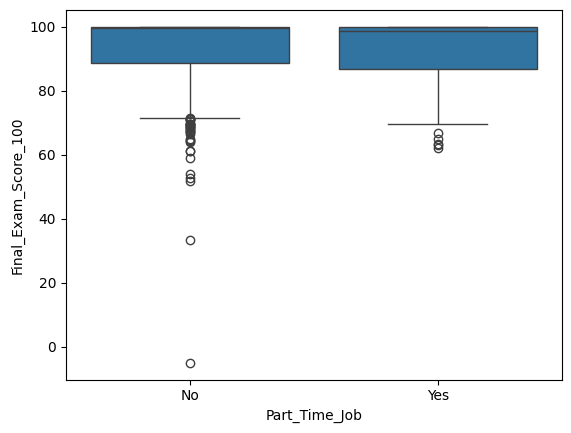

In [31]:
sns.boxplot(x="Part_Time_Job",
            y="Final_Exam_Score_100",
            data=df)

plt.show()

In [33]:
correlation = df[numerical_columns].corr()

correlation

,Age,Year_of_Study,Study_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Media_Hours_Per_Day,Attendance_Percentage,Assignment_Delay_Days,Internal_Marks_50,Previous_GPA_10,Monthly_Family_Income_INR,Stress_Level_10,Final_Exam_Score_100
Age,1.000000,-0.041874,0.017520,0.062329,0.026706,0.013446,0.024308,0.046067,0.039037,0.066900,0.011317,0.039881
Year_of_Study,-0.041874,1.000000,-0.011368,0.023306,0.013612,0.007589,-0.014441,0.021116,0.038938,0.047889,-0.073971,0.004651
Study_Hours_Per_Day,0.017520,-0.011368,1.000000,0.019978,0.037514,0.175285,-0.042789,0.451431,0.480601,-0.059121,-0.014192,0.327315
Sleep_Hours_Per_Day,0.062329,0.023306,0.019978,1.000000,0.070955,-0.033784,0.029878,-0.045681,-0.085445,-0.078514,-0.110027,-0.069697
Social_Media_Hours_Per_Day,0.026706,0.013612,0.037514,0.070955,1.000000,-0.128563,-0.012748,-0.058859,-0.201473,-0.017890,0.341348,-0.225360
Attendance_Percentage,0.013446,0.007589,0.175285,-0.033784,-0.128563,1.000000,-0.034647,0.289594,0.453214,0.032276,-0.104656,0.434441
Assignment_Delay_Days,0.024308,-0.014441,-0.042789,0.029878,-0.012748,-0.034647,1.000000,-0.215792,-0.012199,0.037287,0.606845,-0.236236
Internal_Marks_50,0.046067,0.021116,0.451431,-0.045681,-0.058859,0.289594,-0.215792,1.000000,0.386744,-0.014840,-0.165742,0.547630
Previous_GPA_10,0.039037,0.038938,0.480601,-0.085445,-0.201473,0.453214,-0.012199,0.386744,1.000000,0.017029,-0.117939,0.501144
Monthly_Family_Income_INR,0.066900,0.047889,-0.059121,-0.078514,-0.017890,0.032276,0.037287,-0.014840,0.017029,1.000000,0.008424,-0.029953


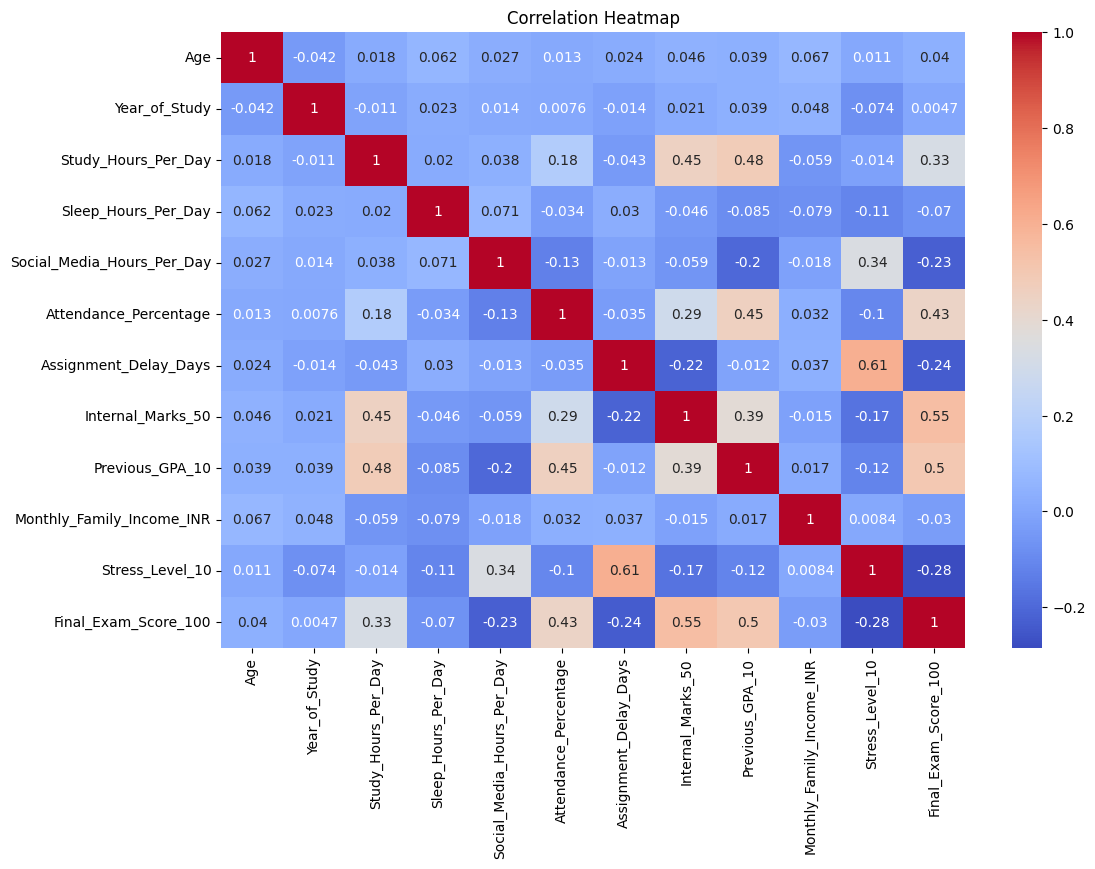

In [34]:
plt.figure(figsize=(12,8))

sns.heatmap(correlation,
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

In [36]:
z = np.abs(zscore(df[numerical_columns]))

np.where(z > 3)

(array([ 14,  15,  26,  46,  49,  58, 102, 122, 136, 156, 207, 240, 243,
        273, 276, 285, 291, 291, 295, 306, 339, 343, 351, 355, 358, 366,
        386, 414, 434, 438, 452, 463, 463, 464, 468, 474, 479, 501, 530,
        541, 544, 546, 555, 556, 560, 568, 599, 615, 616, 636, 640, 653,
        658, 670, 676, 677, 677, 679, 688, 693, 694, 697]),
 array([ 7,  6,  4,  0,  4,  2,  2,  4, 11,  6, 11,  6,  2,  6,  5,  2,  6,
        11,  9,  0,  6,  2,  6,  2,  2,  5,  0, 11,  3,  3,  9,  2,  4,  0,
         5,  6,  2,  4,  2,  2,  7,  9, 11,  5,  6,  7,  7,  9,  9, 11,  4,
         4,  5,  2,  6,  6,  7,  5,  7,  4,  4,  6]))

In [37]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)

    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR

    upper = Q3 + 1.5*IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col)

    print("Outliers :",len(outliers))

Age
Outliers : 8
Year_of_Study
Outliers : 0
Study_Hours_Per_Day
Outliers : 21
Sleep_Hours_Per_Day
Outliers : 3
Social_Media_Hours_Per_Day
Outliers : 25
Attendance_Percentage
Outliers : 9
Assignment_Delay_Days
Outliers : 36
Internal_Marks_50
Outliers : 4
Previous_GPA_10
Outliers : 1
Monthly_Family_Income_INR
Outliers : 31
Stress_Level_10
Outliers : 9
Final_Exam_Score_100
Outliers : 34


In [38]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)

    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR

    upper = Q3 + 1.5*IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

In [39]:
df = pd.get_dummies(df, drop_first=True)

In [40]:
scaler = StandardScaler()

num_cols = df.select_dtypes(include=['int64','float64']).columns

df[num_cols] = scaler.fit_transform(df[num_cols])

In [ ]:
# • The dataset provides information about students' academic, personal, and lifestyle factors.
# • Data cleaning removed missing values and duplicate records, improving data quality.
# • Univariate analysis explained the distribution of individual features.
# • Bivariate analysis explored how study habits, attendance, GPA, and lifestyle factors relate to final exam scores.
# • Correlation analysis identified the strongest relationships among numerical variables.
# • Outlier detection highlighted unusual observations and removed extreme values using the IQR method.
# • Feature engineering encoded categorical variables and standardized numerical features.